
# CS 370 Assignment 4 — Q4

This notebook solves Q4 of Assignment 4.

It does the following:
1. Load the polluted sound signal `train_bird.wav`.
2. Plot the original signal in the time domain.
3. Compute and plot the DFT / power spectrum.
4. Build a low-pass filter manually in the frequency domain to isolate the train whistle.
5. Build the corresponding high-pass filter manually to isolate the bird chirps.
6. Plot the denoised signals and their power spectra.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy.io import wavfile

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True


In [5]:
Fs, y = wavfile.read('train_bird.wav')

print("Sampling rate Fs =", Fs)
print("Signal shape =", y.shape)
print("dtype =", y.dtype)

# Convert to float for FFT/filtering
y = np.array(y, dtype=float)

# If stereo, convert to mono
if y.ndim == 2:
    y = y.mean(axis=1)

N = len(y)
t = np.arange(N) / Fs

print("N =", N)
print("Duration =", N / Fs, "seconds")
display(Audio(y, rate=Fs))


Sampling rate Fs = 8192
Signal shape = (12880,)
dtype = int16
N = 12880
Duration = 1.572265625 seconds


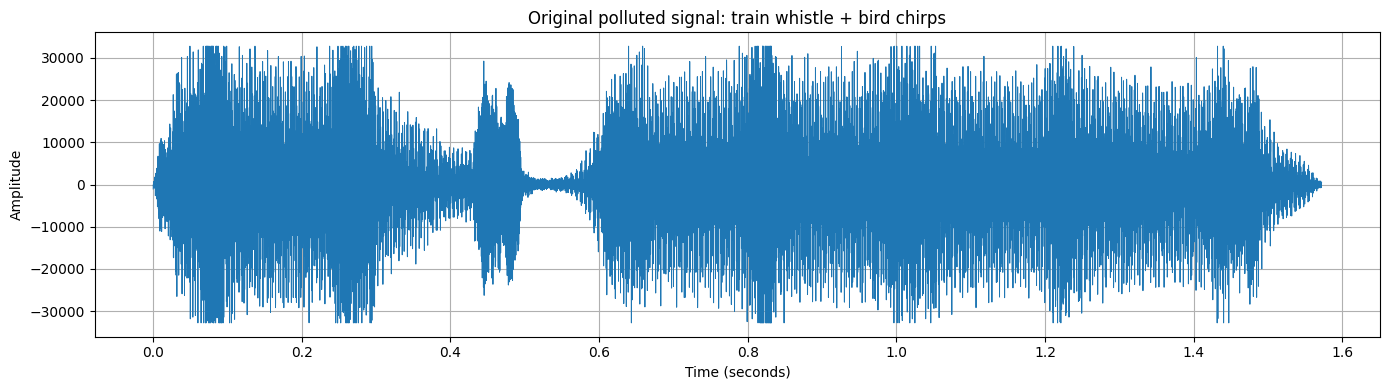

In [6]:

plt.figure(figsize=(14,4))
plt.plot(t, y, linewidth=0.7)
plt.title('Original polluted signal: train whistle + bird chirps')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()


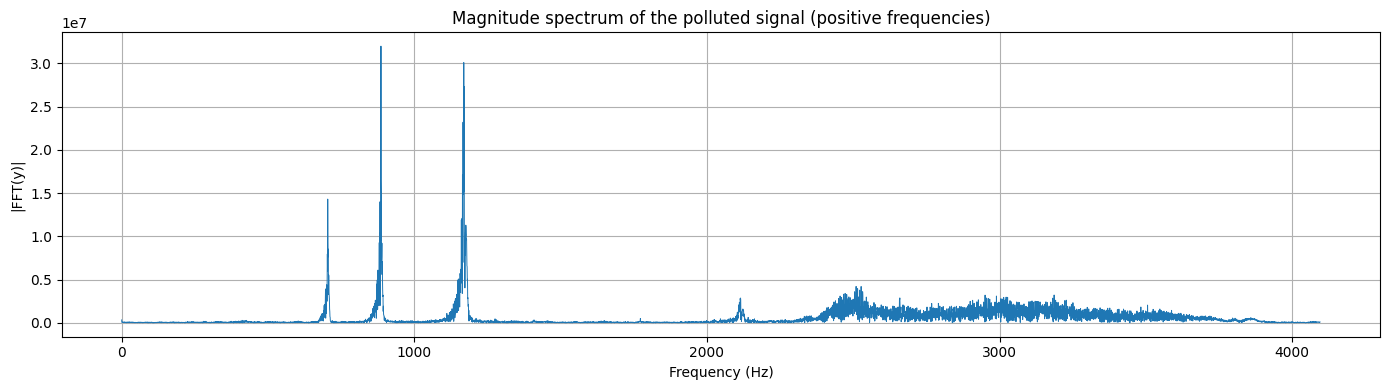

In [7]:

Y = np.fft.fft(y)
magY = np.abs(Y)
freq = np.arange(N) * Fs / N

plt.figure(figsize=(14,4))
plt.plot(freq[:N//2], magY[:N//2], linewidth=0.7)
plt.title('Magnitude spectrum of the polluted signal (positive frequencies)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('|FFT(y)|')
plt.tight_layout()
plt.show()



## Choose a cutoff frequency

You should inspect the spectrum above and then choose a cutoff index `p` by trial and error.

A low-pass mask keeps:
- indices `0,1,...,p`
- and the conjugate-symmetric high-end indices `N-p, ..., N-1`

and zeros out everything in between.

The corresponding high-pass mask is `1 - lowpass_mask`, except that the DC term remains zero in the high-pass signal.


In [8]:

# ==========================================================
# Adjust p after inspecting the power spectrum.
# This is the MAIN tuning parameter for the separation.
# ==========================================================
p = 900

Q_low = np.ones(N)
Q_low[p+1:N-p] = 0

Q_high = np.zeros(N)
Q_high[p+1:N-p] = 1
Q_high[0] = 0
Q_high[p] = 0
Q_high[N-p] = 0

Y_train = Y * Q_low
Y_bird  = Y * Q_high

train_sig = np.real(np.fft.ifft(Y_train))
bird_sig  = np.real(np.fft.ifft(Y_bird))

print("Chosen cutoff index p =", p)
print("Approx cutoff frequency =", p * Fs / N, "Hz")


Chosen cutoff index p = 900
Approx cutoff frequency = 572.4223602484471 Hz


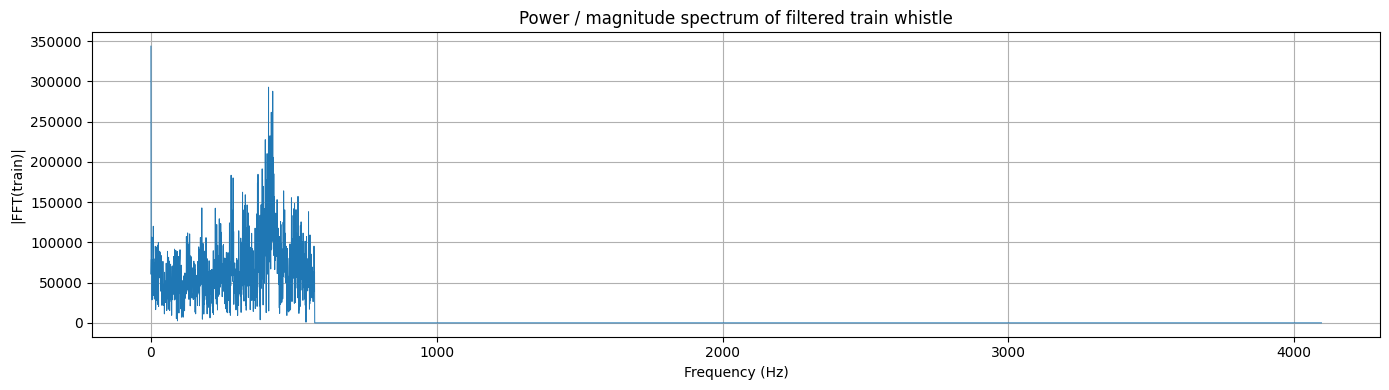

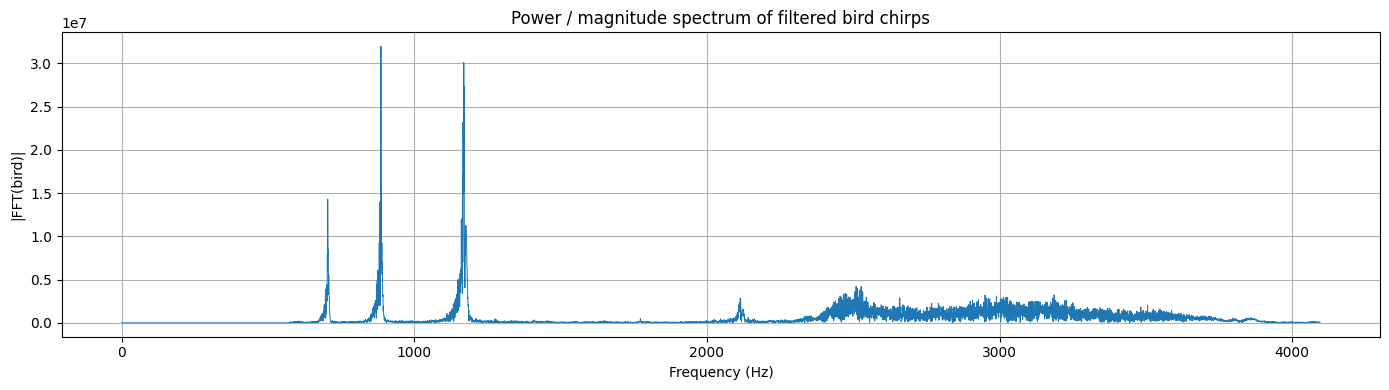

In [9]:

plt.figure(figsize=(14,4))
plt.plot(freq[:N//2], np.abs(Y_train[:N//2]), linewidth=0.7)
plt.title('Power / magnitude spectrum of filtered train whistle')
plt.xlabel('Frequency (Hz)')
plt.ylabel('|FFT(train)|')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14,4))
plt.plot(freq[:N//2], np.abs(Y_bird[:N//2]), linewidth=0.7)
plt.title('Power / magnitude spectrum of filtered bird chirps')
plt.xlabel('Frequency (Hz)')
plt.ylabel('|FFT(bird)|')
plt.tight_layout()
plt.show()


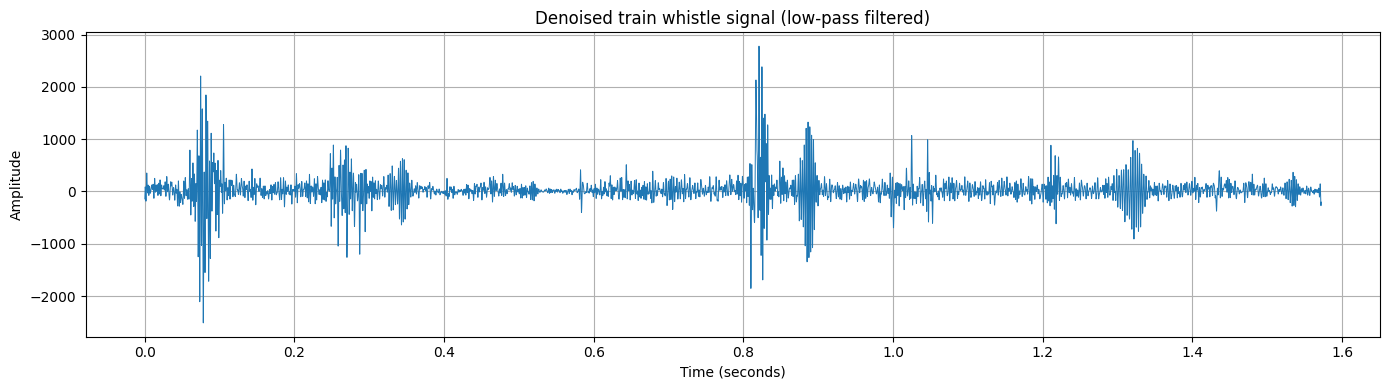

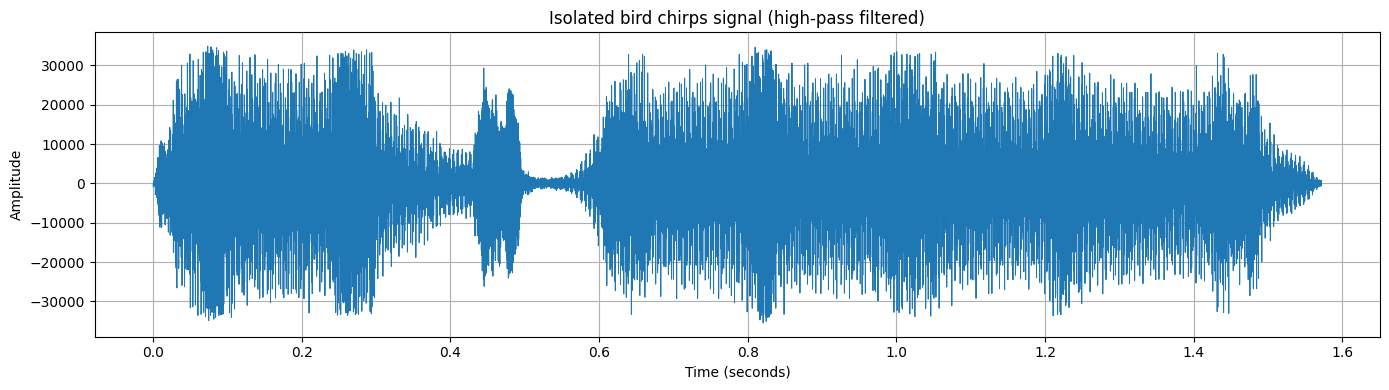

In [10]:

plt.figure(figsize=(14,4))
plt.plot(t, train_sig, linewidth=0.7)
plt.title('Denoised train whistle signal (low-pass filtered)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14,4))
plt.plot(t, bird_sig, linewidth=0.7)
plt.title('Isolated bird chirps signal (high-pass filtered)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()


In [11]:

print("Listen to the filtered train whistle:")
display(Audio(train_sig, rate=Fs))

print("Listen to the filtered bird chirps:")
display(Audio(bird_sig, rate=Fs))


Listen to the filtered train whistle:


Listen to the filtered bird chirps:


In [12]:

# Optional: save the separated sounds
wavfile.write('train_filtered.wav', Fs, np.int16(np.clip(train_sig, -32768, 32767)))
wavfile.write('bird_filtered.wav', Fs, np.int16(np.clip(bird_sig, -32768, 32767)))

print("Saved train_filtered.wav and bird_filtered.wav")


Saved train_filtered.wav and bird_filtered.wav
